# SDE discovery with sparse Bayesian inference

I use seven simulated stochastic systems to check how well the BISDE implementation recovers their drift equations and diagonal diffusion coefficients. The examples range from simple one-dimensional potentials to three-dimensional chaotic systems.

The simulations and fitting settings come from the scripts in `examples/`. I keep those scripts separate and use this notebook to compare the inferred equations with the ones used to generate the data.

Each experiment uses one fixed random seed, so these are numerical examples rather than a systematic study of estimation accuracy.

## Method

For $dX_t = a(X_t)\,dt + \sqrt{D(X_t)}\,dW_t$, I estimate the drift using the increments $\Delta X/\Delta t$. I then estimate the diagonal diffusion from the squared increments after subtracting the fitted drift contribution.

The candidate functions are tensor-product polynomials. For example, order 3 in three dimensions gives $3^3=27$ terms, including cross terms. BISDE fits each coordinate separately, and the scripts apply a small-coefficient cutoff after fitting.

In the tables, **Extra term** means that the fitted equation contains a term absent from the theoretical equation. Relative error is shown only where the theoretical coefficient is nonzero. The analysis covers diagonal diffusion only; it does not estimate correlations between noise components.

In [1]:
from pathlib import Path
from importlib.util import module_from_spec, spec_from_file_location
from itertools import product
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Works when launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir() or not (ROOT / "examples").is_dir():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/ directory.")
sys.path.insert(0, str(ROOT))

from src.bisde import bisde_pythonic
from src.polynomial_library import polynomial_library, drift_targets, diffusion_targets
from src.simulation import simulate_1d, simulate_2d, simulate_3d


def load_example(filename):
    path = ROOT / "examples" / filename
    spec = spec_from_file_location(path.stem, path)
    module = module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


## Running the examples

The helper functions below load the existing scripts, run their simulations, and put the fitted coefficients into comparable tables. The time steps, sample counts, random seeds, and coefficient cutoffs are kept the same as in the scripts.

In [2]:
def run_experiment(filename, true_terms, true_diffusion, threshold=0.05):
    ex = load_example(filename)
    dim = len(true_terms)
    order = getattr(ex, "ORDER", 10)
    seed = getattr(ex, "SEED", 123 if filename.startswith("02_") else 42)
    x0 = (0 if dim == 1 else
          [0.5, 0.0] if filename.startswith("03_") else
          [1.0, 0.0] if filename.startswith("04_") else
          [1.0, 1.0, 1.0] if filename.startswith("05_") else
          ex.INITIAL)
    simulate = {1: simulate_1d, 2: simulate_2d, 3: simulate_3d}[dim]
    time, trajectory = simulate(ex.drift, ex.diffusion, x0=x0,
                                dt=ex.DT, n_steps=ex.N_STEPS, seed=seed)
    if not np.isfinite(trajectory).all():
        raise RuntimeError(f"Non-finite trajectory in {filename}")
    positions = trajectory[np.newaxis, :] if dim == 1 else trajectory
    phi = polynomial_library(positions, order)
    powers = list(product(range(order), repeat=dim))
    results = []
    rows = []
    for axis in range(dim):
        values = positions[axis]
        drift_coef = bisde_pythonic(phi, drift_targets(values, ex.DT), max_iters=100)
        drift_coef[np.abs(drift_coef) < threshold] = 0
        diff_y = diffusion_targets(values, ex.DT, phi, drift_coef)
        diff_coef = bisde_pythonic(phi, diff_y, max_iters=100)
        diff_coef[np.abs(diff_coef) < threshold] = 0
        results.append((drift_coef, diff_coef))
        expected = true_terms[axis]
        for power, coefficient in zip(powers, drift_coef):
            actual = expected.get(power, 0.0)
            if actual != 0 or coefficient != 0:
                rows.append({"Component": "xyz"[axis], "Term": str(power),
                             "True": actual, "Estimated": float(coefficient),
                             "Relative error (%)": (100 * abs(coefficient - actual) / abs(actual)
                                                    if actual != 0 else np.nan),
                             "Extra term": actual == 0 and coefficient != 0})
        for power, coefficient in zip(powers, diff_coef):
            actual = true_diffusion[axis] if all(p == 0 for p in power) else 0.0
            if actual != 0 or coefficient != 0:
                rows.append({"Component": "D_" + "xyz"[axis], "Term": str(power),
                             "True": actual, "Estimated": float(coefficient),
                             "Relative error (%)": (100 * abs(coefficient - actual) / abs(actual)
                                                    if actual != 0 else np.nan),
                             "Extra term": actual == 0 and coefficient != 0})
    return time, positions, results, pd.DataFrame(rows)


def show_experiment(title, filename, terms, diffusion, threshold=0.05):
    time, positions, estimates, table = run_experiment(filename, terms, diffusion, threshold)
    print(title)
    print(f"Samples: {positions.shape[1]:,} | dt: {time[1]-time[0]:g} | "
          f"candidate terms: {len(estimates[0][0])} | cutoff: {threshold}")
    display(table.round(5))
    fig = plt.figure(figsize=(10, 3.8))
    dim = len(terms)
    if dim == 1:
        ax = fig.add_subplot(121)
        ax.plot(time[:1500], positions[0, :1500], lw=0.8)
        ax.set(xlabel="Time", ylabel="x", title="Trajectory (first 1500 samples)")
        ax2 = fig.add_subplot(122)
        grid = np.linspace(np.percentile(positions[0], 1),
                           np.percentile(positions[0], 99), 250)
        true_curve = sum(c * grid**p[0] for p, c in terms[0].items())
        estimated_curve = sum(c * grid**p[0] for p, c in zip(
            [(i,) for i in range(len(estimates[0][0]))], estimates[0][0]))
        ax2.plot(grid, true_curve, label="True")
        ax2.plot(grid, estimated_curve, "--", label="Estimated")
        ax2.set(xlabel="x", ylabel="Drift", title="Drift comparison")
        ax2.legend()
    elif dim == 2:
        ax = fig.add_subplot(121)
        ax.plot(positions[0, :4000], positions[1, :4000], lw=0.6)
        ax.set(xlabel="x", ylabel="y", title="Trajectory (first 4000 samples)")
        ax2 = fig.add_subplot(122)
        ax2.plot(time[:2000], positions[0, :2000], label="x", lw=0.8)
        ax2.plot(time[:2000], positions[1, :2000], label="y", lw=0.8)
        ax2.set(xlabel="Time", ylabel="Position", title="Coordinate time series")
        ax2.legend()
    else:
        ax = fig.add_subplot(121, projection="3d")
        ax.plot(*positions[:, ::5], lw=0.4)
        ax.set(xlabel="x", ylabel="y", zlabel="z", title="Simulated trajectory")
        ax2 = fig.add_subplot(122)
        for i, name in enumerate("xyz"):
            ax2.plot(time[:2000], positions[i, :2000], label=name, lw=0.8)
        ax2.set(xlabel="Time", ylabel="Position", title="Coordinate time series")
        ax2.legend()
    fig.tight_layout()
    plt.show()
    return table

all_results = {}


## 1. 1D double-well potential

The drift is $a(x)=0.64x-0.0256x^3$, with $D(x)=2$. This example tests whether the method can recover both a linear and a cubic term.

1D double-well potential
Samples: 80,000 | dt: 0.04 | candidate terms: 10 | cutoff: 0.02


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(1,)",0.6400,0.62405,2.49244,False
1,x,"(3,)",-0.0256,-0.02505,2.15716,False
2,D_x,"(0,)",2.0000,2.01125,0.56248,False


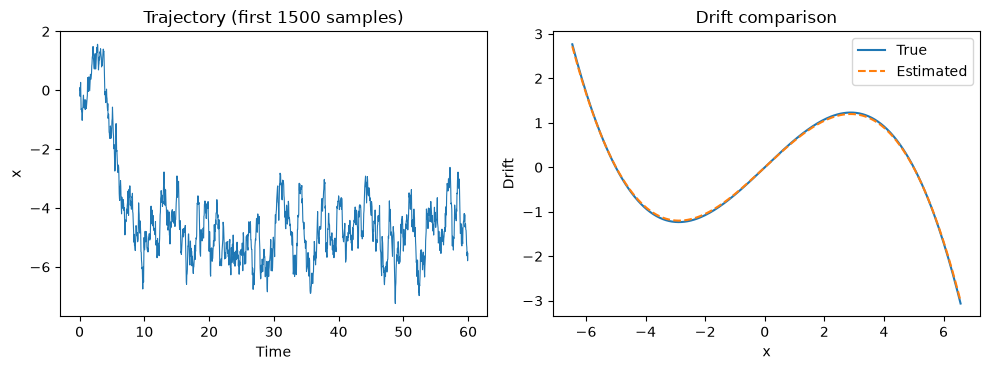

In [3]:
all_results['1D double-well potential'] = show_experiment(
    '1D double-well potential', '01_double_well_1d.py',
    [{(1,): 0.64, (3,): -0.0256}], [2.0], threshold=0.02
)

**Observation.** In the run checked while preparing this notebook, the linear and cubic drift terms were recovered without additional selected terms. The estimated diffusion was also close to 2.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 2. 1D harmonic oscillator

Here $a(x)=-3x$ and $D(x)=2$. Since the drift is linear, any other selected polynomial term is an extra term.

1D harmonic oscillator
Samples: 50,000 | dt: 0.04 | candidate terms: 10 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(1,)",-3.0,-3.09148,3.04928,False
1,x,"(2,)",0.0,0.05575,NaN,True
2,D_x,"(0,)",2.0,1.99968,0.01590,False
3,D_x,"(1,)",0.0,0.05222,NaN,True


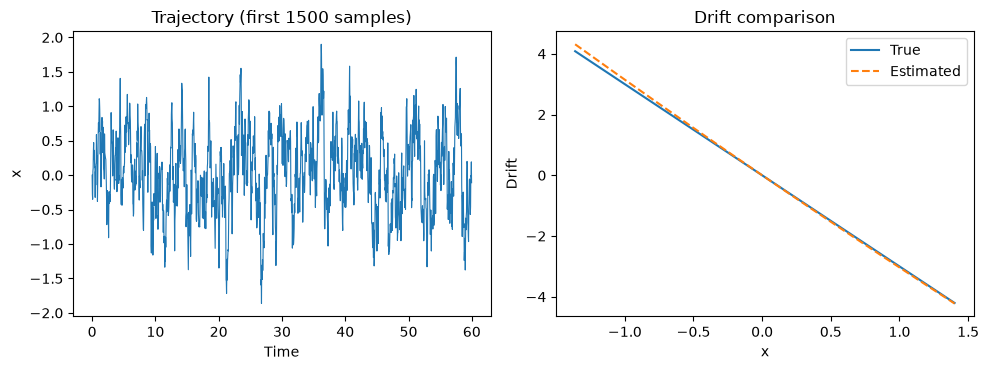

In [4]:
all_results['1D harmonic oscillator'] = show_experiment(
    '1D harmonic oscillator', '02_harmonic_oscillator_1d.py',
    [{(1,): -3.0}], [2.0], threshold=0.05
)

**Observation.** The main linear drift coefficient was close to $-3$, but a few additional terms appeared in some runs. This is a useful example of the difference between estimating a coefficient accurately and selecting exactly the right equation.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 3. 2D double-well potential

The drift components are $a_x=4x-4x^3$ and $a_y=-2y$, with diagonal diffusion $(2,2)$. The two coordinates have different drift structures.

2D double-well potential
Samples: 100,000 | dt: 0.005 | candidate terms: 16 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(1, 0)",4.0,3.83951,4.01233,False
1,x,"(3, 0)",-4.0,-3.82204,4.44889,False
2,D_x,"(0, 0)",2.0,2.00391,0.19562,False
3,y,"(0, 1)",-2.0,-2.04006,2.00320,False
4,D_y,"(0, 0)",2.0,2.03455,1.72760,False


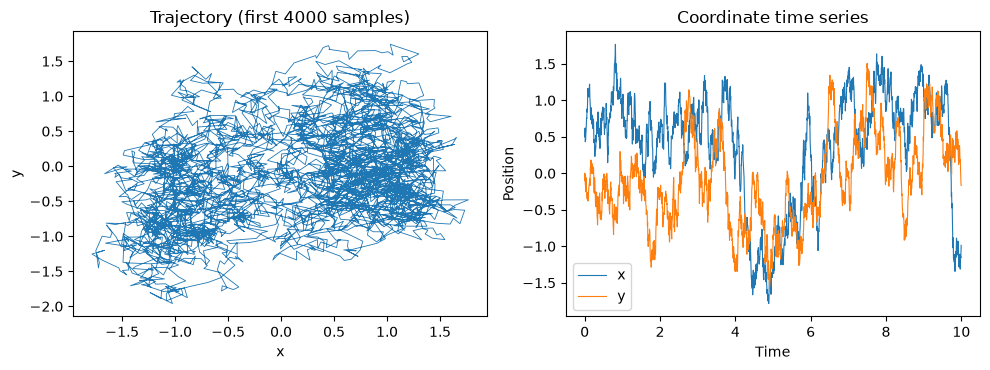

In [5]:
all_results['2D double-well potential'] = show_experiment(
    '2D double-well potential', '03_double_well_2d.py',
    [{(1,0): 4.0, (3,0): -4.0}, {(0,1): -2.0}], [2.0, 2.0], threshold=0.05
)

**Observation.** The earlier run recovered $4x-4x^3$ and $-2y$ with no additional selected terms. Both estimated diffusion coefficients were close to 2.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 4. 2D harmonic oscillator

This system has coupled linear drift: $a_x=-3x+5y$ and $a_y=-5x-3y$. Both diffusion coefficients are 2.

2D harmonic oscillator
Samples: 80,000 | dt: 0.01 | candidate terms: 16 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(0, 1)",5.0,4.96387,0.72257,False
1,x,"(1, 0)",-3.0,-3.10921,3.64030,False
2,x,"(3, 0)",0.0,0.09865,NaN,True
3,D_x,"(0, 0)",2.0,2.00916,0.45805,False
4,y,"(0, 1)",-3.0,-2.88270,3.91008,False
5,y,"(1, 0)",-5.0,-4.95242,0.95156,False
6,y,"(1, 1)",0.0,-0.10257,NaN,True
7,y,"(2, 3)",0.0,-0.08885,NaN,True
8,y,"(3, 0)",0.0,-0.06837,NaN,True
9,y,"(3, 1)",0.0,-0.19221,NaN,True


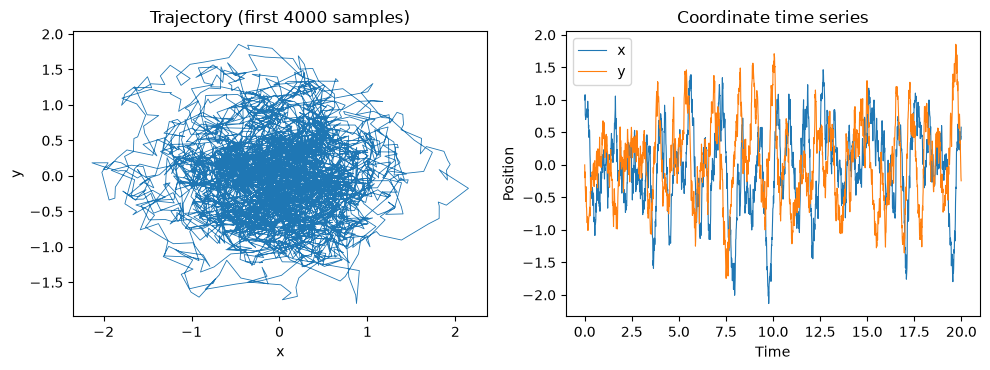

In [6]:
all_results['2D harmonic oscillator'] = show_experiment(
    '2D harmonic oscillator', '04_harmonic_oscillator_2d.py',
    [{(1,0): -3.0, (0,1): 5.0}, {(1,0): -5.0, (0,1): -3.0}], [2.0, 2.0], threshold=0.05
)

**Observation.** The main linear terms were recovered, but the earlier fit also selected several nonlinear terms. The diffusion estimates remained close to 2. This was one of the less clean results in terms of term selection.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 5. 3D Lorenz system

For Lorenz, $a_x=-10x+10y$, $a_y=28x-y-xz$, and $a_z=xy-\frac{8}{3}z$. The diagonal diffusion is $(2,2,2)$.

3D Lorenz system
Samples: 30,000 | dt: 0.001 | candidate terms: 27 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(0, 1, 0)",10.00000,10.11257,1.12566,False
1,x,"(1, 0, 0)",-10.00000,-10.18395,1.83951,False
2,D_x,"(0, 0, 0)",2.00000,2.04087,2.04332,False
3,y,"(0, 1, 0)",-1.00000,-0.95915,4.08530,False
4,y,"(1, 0, 0)",28.00000,28.07688,0.27457,False
5,y,"(1, 0, 1)",-1.00000,-1.00289,0.28939,False
6,D_y,"(0, 0, 0)",2.00000,1.99858,0.07092,False
7,z,"(0, 0, 0)",0.00000,0.29435,NaN,True
8,z,"(0, 0, 1)",-2.66667,-2.68602,0.72556,False
9,z,"(1, 1, 0)",1.00000,0.99916,0.08371,False


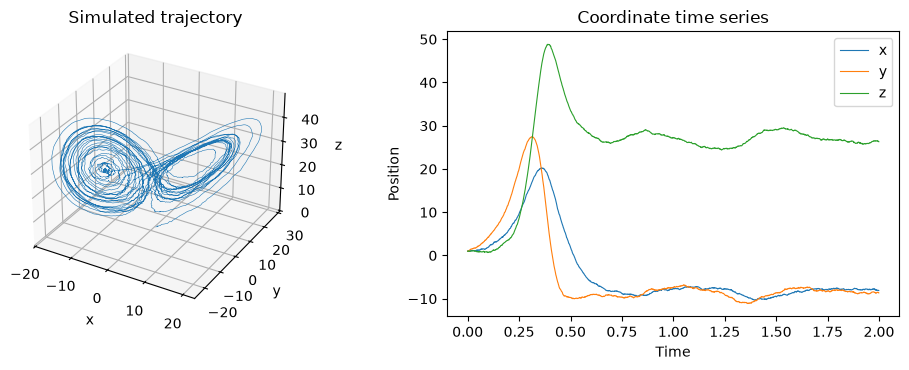

In [7]:
all_results['3D Lorenz system'] = show_experiment(
    '3D Lorenz system', '05_lorenz_3d.py',
    [{(1,0,0): -10.0, (0,1,0): 10.0}, {(1,0,0): 28.0, (0,1,0): -1.0, (1,0,1): -1.0}, {(1,1,0): 1.0, (0,0,1): -8/3}], [2.0, 2.0, 2.0], threshold=0.05
)

**Observation.** The earlier Lorenz run recovered all the main drift terms. It also selected a small constant term in the $z$ equation (about 0.29), while the three diffusion estimates stayed close to 2.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 6. 3D Four-Wing system

The drift is $a_x=0.2x+yz$, $a_y=0.1x-0.4y-xz$, and $a_z=-z-xy$. Each diagonal diffusion coefficient is 0.1.

3D Four-Wing system
Samples: 30,000 | dt: 0.01 | candidate terms: 27 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(0, 1, 1)",1.0,0.95351,4.64947,False
1,x,"(1, 0, 0)",0.2,0.20118,0.58993,False
2,x,"(1, 2, 0)",0.0,0.08071,NaN,True
3,x,"(2, 0, 2)",0.0,-0.08145,NaN,True
4,x,"(2, 1, 1)",0.0,0.09563,NaN,True
5,x,"(2, 2, 0)",0.0,0.05038,NaN,True
6,D_x,"(0, 0, 0)",0.1,0.10199,1.98575,False
7,y,"(0, 1, 0)",-0.4,-0.38051,4.87194,False
8,y,"(1, 0, 0)",0.1,0.07281,27.18892,False
9,y,"(1, 0, 1)",-1.0,-0.98484,1.51593,False


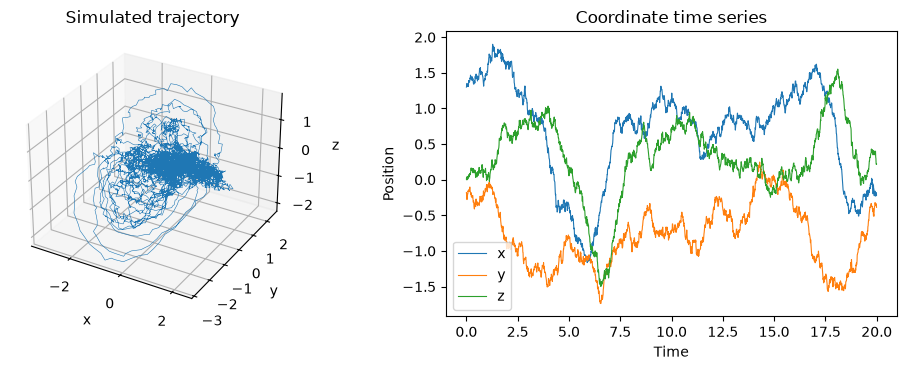

In [8]:
all_results['3D Four-Wing system'] = show_experiment(
    '3D Four-Wing system', '06_four_wing_3d.py',
    [{(1,0,0): 0.2, (0,1,1): 1.0}, {(1,0,0): 0.1, (0,1,0): -0.4, (1,0,1): -1.0}, {(0,0,1): -1.0, (1,1,0): -1.0}], [0.1, 0.1, 0.1], threshold=0.05
)

**Observation.** The earlier Four-Wing run recovered the expected terms, but it also selected additional polynomial terms in the $x$ and $z$ equations. The $0.1x$ term in the $y$ equation had a noticeably larger relative error than the other main coefficients.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## 7. 3D Halvorsen system

The drift components are $a_x=-1.89x-4y-4z-y^2$, $a_y=-4x-1.89y-4z-z^2$, and $a_z=-4x-4y-1.89z-x^2$. The diagonal diffusion is $(0.1,0.1,0.1)$.

3D Halvorsen system
Samples: 30,000 | dt: 0.01 | candidate terms: 27 | cutoff: 0.05


,Component,Term,True,Estimated,Relative error (%),Extra term
0,x,"(0, 0, 1)",-4.00,-3.99453,0.13675,False
1,x,"(0, 1, 0)",-4.00,-4.00091,0.02276,False
2,x,"(0, 2, 0)",-1.00,-0.99998,0.00236,False
3,x,"(1, 0, 0)",-1.89,-1.89044,0.02304,False
4,D_x,"(0, 0, 0)",0.10,0.10206,2.06252,False
5,y,"(0, 0, 1)",-4.00,-3.99966,0.00849,False
6,y,"(0, 0, 2)",-1.00,-0.99972,0.02807,False
7,y,"(0, 1, 0)",-1.89,-1.88609,0.20668,False
8,y,"(1, 0, 0)",-4.00,-3.99974,0.00655,False
9,D_y,"(0, 0, 0)",0.10,0.09993,0.06608,False


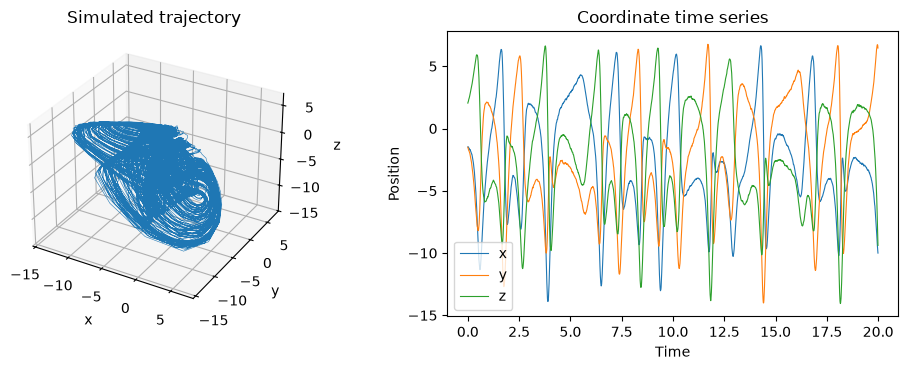

In [9]:
all_results['3D Halvorsen system'] = show_experiment(
    '3D Halvorsen system', '07_halvorsen_3d.py',
    [{(1,0,0): -1.89, (0,1,0): -4.0, (0,0,1): -4.0, (0,2,0): -1.0}, {(1,0,0): -4.0, (0,1,0): -1.89, (0,0,1): -4.0, (0,0,2): -1.0}, {(1,0,0): -4.0, (0,1,0): -4.0, (0,0,1): -1.89, (2,0,0): -1.0}], [0.1, 0.1, 0.1], threshold=0.05
)

**Observation.** In the earlier Halvorsen run, the selected drift terms matched the theoretical equations, with no additional terms. The estimated coefficients were particularly close to their theoretical values, and diffusion estimates were near 0.1.

These observations refer to the earlier fixed-seed runs; check the tables above for the output from your current run.

## Summary across systems

The table below counts recovered theoretical drift terms and additional selected terms. It also reports the largest relative error among the expected coefficients. A small error does not necessarily mean that the method selected only the correct terms.

In [10]:
summary = []
for name, table in all_results.items():
    true_rows = table[table["True"] != 0]
    drift_rows = true_rows[~true_rows["Component"].str.startswith("D_")]
    diffusion_rows = true_rows[true_rows["Component"].str.startswith("D_")]
    summary.append({
        "System": name,
        "True drift terms recovered": int((drift_rows["Estimated"] != 0).sum()),
        "Total true drift terms": len(drift_rows),
        "Extra drift terms": int(table.loc[~table["Component"].str.startswith("D_"), "Extra term"].sum()),
        "Extra diffusion terms": int(table.loc[table["Component"].str.startswith("D_"), "Extra term"].sum()),
        "Max drift relative error (%)": drift_rows["Relative error (%)"].max(),
        "Max diffusion relative error (%)": diffusion_rows["Relative error (%)"].max(),
    })
summary_df = pd.DataFrame(summary)
display(summary_df.round(3))

,System,True drift terms recovered,Total true drift terms,Extra drift terms,Extra diffusion terms,Max drift relative error (%),Max diffusion relative error (%)
0,1D double-well potential,2,2,0,0,2.492,0.562
1,1D harmonic oscillator,1,1,1,1,3.049,0.016
2,2D double-well potential,3,3,0,0,4.449,1.728
3,2D harmonic oscillator,4,4,5,0,3.910,1.116
4,3D Lorenz system,7,7,1,0,4.085,2.043
5,3D Four-Wing system,7,7,5,0,27.189,1.986
6,3D Halvorsen system,12,12,0,0,0.440,2.063


## Discussion

The seven examples show that the method can recover the main drift and diagonal diffusion terms for a range of simulated systems. Term selection is less consistent: some fits retain additional polynomial terms even when the expected coefficients are reasonably accurate. The 2D oscillator and Four-Wing examples illustrate this particularly well, while Halvorsen gave a much cleaner fit in the run I checked.

There are a few limits to these results. Each system is evaluated using one simulated trajectory and one random seed. The fitted equations can change with the time step, number of observations, polynomial library, Bayesian iteration limit, and the cutoff applied to small coefficients. For chaotic systems, the numerical integration step can also affect the trajectories used for fitting. I have not tested sensitivity across multiple seeds or estimated uncertainty intervals here.

The polynomial library includes powers up to `order - 1` in **each coordinate**, not just terms with a limited total degree. That explains why some of the extra selected terms can be relatively high-order combinations.

### Reproducing the results

Run the notebook with the repository's Python environment. It expects the seven scripts in `examples/` and the shared code in `src/`. The coefficient tables and figures are generated when the cells run; no numerical outputs are stored in this file.